# Loading Libraries and Data

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn import metrics, preprocessing
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline

!pip install dmba
from dmba import gainsChart, liftChart
from dmba import adjusted_r2_score, AIC_score, BIC_score
from dmba import classificationSummary, regressionSummary
from dmba import backward_elimination, forward_selection, stepwise_selection, exhaustive_search

import matplotlib.pylab as plt
import seaborn as sns
from pandas.plotting import scatter_matrix, parallel_coordinates
%matplotlib inline

In [ ]:
# Mounting the Google Drive, the file path might be different for each of us
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load SBA_clean2 data created in classification trees (additonal predictors dropped)

In [ ]:
# Load dataset
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv')
# Make copy of data
SBA_df2 = SBA_df.copy()
SBA_df2.head()

,UrbanRural,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession
0,0,0,60000.0,0,48000.0,Below 10 years,0
1,0,0,40000.0,0,32000.0,Below 10 years,0
2,0,0,287000.0,0,215250.0,Above 10 years,0
3,0,0,517000.0,0,387750.0,Below 10 years,0
4,0,0,45000.0,0,36000.0,Below 10 years,0


In [ ]:
# List of variables with only two categories; we want to drop one dummy to avoid redundancy
two_option_vars = ['RevLineCr', 'Term_Category', 'Recession']

# Loop to create dummies for variables with 2 options (drop_first=True)
for col in two_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=True, dtype=int)

# List of remaining categorical variables for which we create full dummy sets
multi_option_vars = ['UrbanRural']

# Loop to create dummies for other categorical variables (drop_first=False)
for col in multi_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=False, dtype=int)

# Display the head of the dataframe to verify the changes
SBA_df2.head()

,DisbursementGross,MIS_Status,SBA_Appv,RevLineCr_1,Term_Category_Below 10 years,Recession_1,UrbanRural_0,UrbanRural_1,UrbanRural_2
0,60000.0,0,48000.0,0,1,0,1,0,0
1,40000.0,0,32000.0,0,1,0,1,0,0
2,287000.0,0,215250.0,0,0,0,1,0,0
3,517000.0,0,387750.0,0,1,0,1,0,0
4,45000.0,0,36000.0,0,1,0,1,0,0


In [ ]:
# Split into 60/40 data
train_df, valid_df = train_test_split(SBA_df2, test_size=0.4, random_state=1)
print(train_df.shape, valid_df.shape)

(284117, 9) (189412, 9)


In [ ]:
# Split train and valid into X and y, non-normalized data
train_Xnon = train_df.drop(columns =['MIS_Status'],axis = 1)
train_ynon = train_df['MIS_Status']
valid_Xnon = valid_df.drop(columns =['MIS_Status'],axis = 1)
valid_ynon = valid_df['MIS_Status']
print(train_Xnon.shape, train_ynon.shape, valid_Xnon.shape, valid_ynon.shape)

(284117, 8) (284117,) (189412, 8) (189412,)


For kNN need to normalize the data.

In [ ]:
# List of numeric columns (you have 4 numeric variables)
numeric__train_df = train_df[[ 'DisbursementGross', 'SBA_Appv']]
numeric_valid_df = valid_df[[ 'DisbursementGross', 'SBA_Appv']]

# Dataframe of categoric variables
categorical__train_df = train_df.drop(columns =['DisbursementGross', 'SBA_Appv', 'MIS_Status'],axis = 1)
categorial_valid_df = valid_df.drop(columns =['DisbursementGross', 'SBA_Appv', 'MIS_Status'],axis = 1)

# Initialize the scaler
scaler = StandardScaler()

# Scale the numeric dataframe
numeric_scaled_train = pd.DataFrame(scaler.fit_transform(numeric__train_df), columns=numeric__train_df.columns)
numeric_scaled_valid = pd.DataFrame(scaler.transform(numeric_valid_df), columns=numeric_valid_df.columns)

# Scale the categorical dataframe
categoric_scaled_train = pd.DataFrame(scaler.fit_transform(categorical__train_df), columns=categorical__train_df.columns)
categoric_scaled_valid = pd.DataFrame(scaler.transform(categorial_valid_df), columns=categorial_valid_df.columns)


# Concat the categorical and numeric
trainNorm = pd.concat([categoric_scaled_train, numeric_scaled_train], axis=1)
validNorm = pd.concat([categoric_scaled_valid, numeric_scaled_valid], axis=1)

# Verify
print("TrainNorm dataframe shape:", trainNorm.shape)
print("ValidNorm dataframe shape:", validNorm.shape)

TrainNorm dataframe shape: (284117, 8)
ValidNorm dataframe shape: (189412, 8)


In [ ]:
# Splitting of data
train_X = trainNorm  # Predictor variables for training
train_y = train_df['MIS_Status']  # Outcome variable for training

valid_X = validNorm  # Predictor variables for validation
valid_y = valid_df['MIS_Status']  # Outcome variable for validation

In [ ]:
# Print Shapes
print(train_X.shape)
print(train_y.shape)
print(valid_X.shape)
print(valid_y.shape)

(284117, 8)
(284117,)
(189412, 8)
(189412,)


In [ ]:
# Check first 5 rows
train_X.head()

,RevLineCr_1,Term_Category_Below 10 years,Recession_1,UrbanRural_0,UrbanRural_1,UrbanRural_2,DisbursementGross,SBA_Appv
0,-0.881279,0.431616,1.614851,-0.549555,0.763834,-0.397602,-0.396815,-0.396053
1,-0.881279,-2.316875,-0.619252,-0.549555,0.763834,-0.397602,1.379988,0.800836
2,-0.881279,0.431616,1.614851,-0.549555,0.763834,-0.397602,-0.565283,-0.504646
3,-0.881279,0.431616,1.614851,-0.549555,0.763834,-0.397602,-0.528580,-0.480987
4,-0.881279,0.431616,-0.619252,-0.549555,0.763834,-0.397602,-0.161548,-0.244401


In [ ]:
# Check first 5 rows
train_y.head()

,MIS_Status
178126,0
244880,0
141699,0
168395,1
626,0


# Fit Model

# Testing various kNNs

In [ ]:
# Train a classifier for different values of k
results = []
for k in range(1, 9):
    knn = KNeighborsClassifier(n_neighbors=k).fit(train_X, train_y)
    results.append({
        'k': k,
        'score': accuracy_score(valid_y, knn.predict(valid_X))
        # accuracy_score() or recall_score()
    })

# Convert results to a pandas data frame
results = pd.DataFrame(results)
results.sort_values(by='score', ascending=False)

,k,score
7,8,0.774254
5,6,0.772279
1,2,0.769254
3,4,0.766805
6,7,0.766055
4,5,0.761567
2,3,0.750180
0,1,0.717367


In [ ]:
# Testing different Ks, at min try up to n = k, using Cross Validation
# concat dataset together
X = pd.concat([train_X, valid_X], axis=0)
y = pd.concat([train_y, valid_y], axis=0)

# Split into 10 folds
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, y, test_size=0.1, random_state=1)

results = []
for k in range(1, 9, 2):

    folds = 10
    scalar = preprocessing.StandardScaler()
    knn = KNeighborsClassifier(n_neighbors=k).fit(Xtrain, Ytrain)
    pipeline = Pipeline([('transformer', scalar), ('estimator', knn)])
    cv = KFold(n_splits=(folds), random_state=1, shuffle=True)
    scores = cross_val_score(pipeline, Xtrain, Ytrain.values.ravel(), scoring='recall', cv = cv)   # ‘recall’ or ‘accuracy’
    results.append({
        'k' : k,
        'score': accuracy_score(Ytest, knn.predict(Xtest))
    })

results = pd.DataFrame(results).sort_values(by=['score'], ascending=False)

print(results)

   k     score
3  7  0.781281
2  5  0.775537
1  3  0.765062
0  1  0.725213


In [ ]:
# Fit Model to K from above
knn = KNeighborsClassifier(n_neighbors=7)

# Create Model
model = knn.fit(train_X, train_y)

In [ ]:
# Test Model
pred = knn.predict(valid_X)
classificationSummary(valid_y, pred)

Confusion Matrix (Accuracy 0.7661)

       Prediction
Actual      0      1
     0 132485  14734
     1  29578  12615


In [ ]:
# y_Pred
y_pred = model.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['KNN'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,KNN,0.46126,0.298983,0.362802,0.899918


Accuracy:  0.7660549490000633


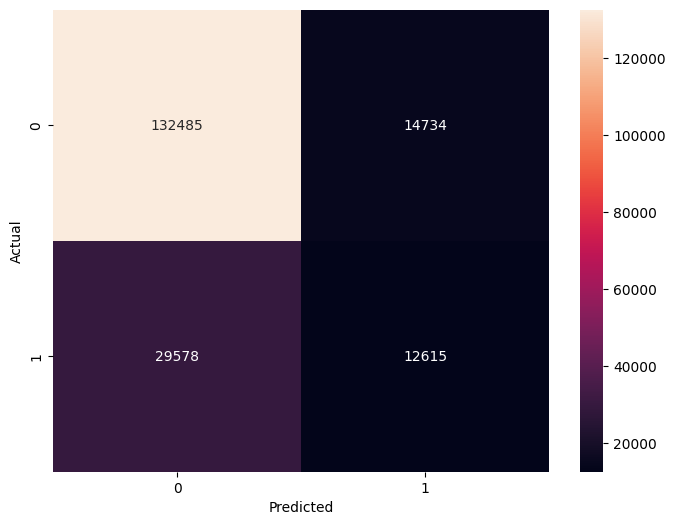

In [ ]:
#Confusion Matrix
y_pred = model.predict(valid_X)
# Convert valid_y to a 1-dimensional array due to error
valid_y_1d = valid_y.values.ravel()
confusion_matrix = pd.crosstab(valid_y_1d, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y_1d, y_pred))
plt.show()

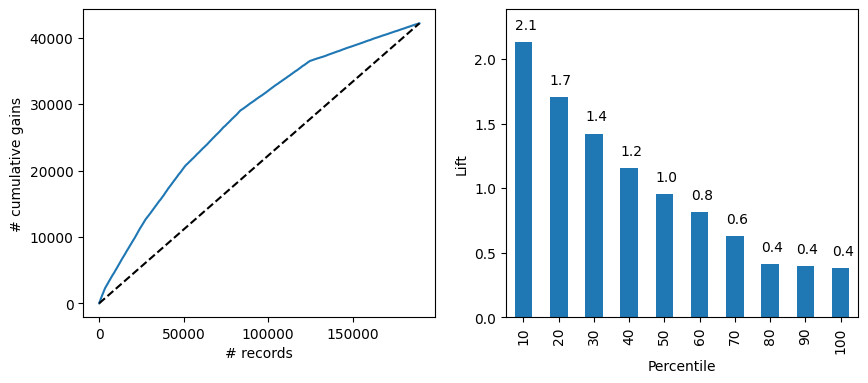

In [ ]:
# Lift and Decile Charts
valid_y_1d = valid_y.values.ravel()

# Step 1: Calculate predicted probabilities for the training set
valid_proba = model.predict_proba(valid_X)

# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y_1d,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': model.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.1 times better in the first decile. The next 20-40% bars also predict better than a random 10% of samples from the data.

# Calculated Net Profit

In [ ]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y).ravel()  # Ensure 1D
pred_y = np.array(model.predict(train_X)).ravel()  # Ensure 1D
net_profit = np.zeros_like(actual_y, dtype=float)

# Reverse normalization
original_train_X = train_Xnon.copy()
original_mean = original_train_X['DisbursementGross'].mean()
original_std = original_train_X['DisbursementGross'].std()
disbursement_gross_original = disbursement_gross * original_std + original_mean

# Ensure mask and assignment shapes match
# Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
mask = (actual_y == 0) & (pred_y == 0)
net_profit[mask] = 0.05 * disbursement_gross_original[mask]

# Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
mask = (actual_y == 1) & (pred_y == 0)
net_profit[mask] = -0.05 * disbursement_gross_original[mask] * 5

# Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
mask = (actual_y == 1) & (pred_y == 1)
net_profit[mask] = 0

# Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
mask = (actual_y == 0) & (pred_y == 1)
net_profit[mask] = 0  # No profit or loss for incorrect "default"

# Calculate total net profit
total_net_profit = np.sum(net_profit)

# Output the total net profit
print(f"Total Net Profit: {total_net_profit:,.2f} USD")

Total Net Profit: 806,636,753.34 USD


In [ ]:
# Get predicted probabilities for the positive class
pred_prob = model.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Ensure actual_y is 1D
actual_y = np.array(train_y).ravel()  # Flatten to 1D array if necessary

# Ensure disbursement_gross is properly shaped
disbursement_gross = np.array(train_X['DisbursementGross'])

# Reverse normalization
original_train_X = train_Xnon.copy()
original_mean = original_train_X['DisbursementGross'].mean()
original_std = original_train_X['DisbursementGross'].std()
disbursement_gross_original = disbursement_gross * original_std + original_mean  # Denormalize

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross_original[mask]  # Use denormalized value

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross_original[mask] * 5  # Use denormalized value

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.15
Maximum Net Profit: 1,214,843,472.46 USD


# Final Results

Given the calculations above, we found that the best k value was 7. We found the best net profit of:

$1,214,843,472.46 at a 15% cutt-off value